# Importando base de dados


In [1]:
from IPython.display import display
import pandas as pd
df = pd.read_csv("vendas.csv",sep=";")
print(df.head())


   id_item_venda  id_pedido           data_venda          nome_produto  \
0              1      10000  2021-08-17 00:00:00   Mouse Gamer 10k DPI   
1              2      10000  2021-08-17 00:00:00  Smartphone Premium X   
2              3      10001  2021-02-24 00:00:00       Smart TV 55" 4K   
3              4      10002  2022-11-28 00:00:00        Monitor 27" 4K   
4              5      10002  2022-11-28 00:00:00  Teclado Mecânico RGB   

  categoria_produto  quantidade  preco_unitario  desconto  valor_total  \
0       Informática           1           250.0      0.00       250.00   
1       Eletrônicos           1          4500.0      0.00      4500.00   
2       Eletrônicos           1          3100.0    587.85      2512.15   
3       Informática           1          2100.0      0.00      2100.00   
4       Informática           1           550.0     69.14       480.86   

     nome_cliente  cidade_cliente estado_cliente   nome_vendedor  \
0  Rafael Pereira   Caxias do Sul         

# 1. Exploração Inicial

In [3]:
# Quantidade de registros e colunas
print("Total de registros:", df.shape[0])
print("Total de colunas:", df.shape[1])

# Tipos de dados
print("\nTipos de dados:")
print(df.dtypes)

# Valores ausentes
print("\nValores ausentes:")
print(df.isnull().sum())

# Registros duplicados
print("\nRegistros duplicados:", df.duplicated().sum())

# Resumo estatístico
display(df.describe())

Total de registros: 50000
Total de colunas: 15

Tipos de dados:
id_item_venda          int64
id_pedido              int64
data_venda               str
nome_produto             str
categoria_produto        str
quantidade             int64
preco_unitario       float64
desconto             float64
valor_total          float64
nome_cliente             str
cidade_cliente           str
estado_cliente           str
nome_vendedor            str
forma_pagamento          str
status_venda             str
dtype: object

Valores ausentes:
id_item_venda          0
id_pedido              0
data_venda             0
nome_produto           0
categoria_produto      0
quantidade             0
preco_unitario         0
desconto               0
valor_total            0
nome_cliente           0
cidade_cliente       150
estado_cliente         0
nome_vendedor          0
forma_pagamento        0
status_venda           0
dtype: int64

Registros duplicados: 150


,id_item_venda,id_pedido,quantidade,preco_unitario,desconto,valor_total
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000
mean,24927.515980,24268.761320,1.485260,1849.68727,172.894776,2597.498904
std,14389.854334,8235.726963,1.213792,2158.36151,698.760053,4575.844584
min,1.000000,10000.000000,-5.000000,45.00000,0.000000,-21000.000000
25%,12467.750000,17158.750000,1.000000,299.90000,0.000000,414.575000
50%,24927.500000,24241.500000,1.000000,999.00000,0.000000,1284.115000
75%,37385.250000,31401.250000,2.000000,2800.00000,101.872500,2997.000000
max,49850.000000,38536.000000,10.000000,8500.00000,42000.000000,85000.000000


### Conclusão

A exploração inicial identificou 50.000 registros,
dos quais 150 estão duplicados. Também foram encontrados
150 valores ausentes na coluna cidade_cliente.

A análise estatística revelou possíveis inconsistências,
como quantidades e valores totais negativos, que deverão
ser investigados durante o tratamento dos dados.

# 2. Tratamento de Dados:
Identifique e trate valores ausentes, registros duplicados e quaisquer
inconsistências lógicas presentes nas colunas (como datas inválidas ou erros de digitação).
Documente quais decisões você tomou para tratar esses problemas.

In [4]:
#Remoçao de duplicados
df = df.drop_duplicates().copy()

print("Total de registros:", len(df))

#Tratamento de valores ausentes
df["cidade_cliente"] =  df["cidade_cliente"].fillna("Não informada")
print(df.isnull().sum())

#conversão de datas
df["data_venda"] =  pd.to_datetime(
    df["data_venda"], errors="coerce"
)
print("Total de registros:", df["data_venda"].isnull().sum())

#verificando inconsistências
print("Quantidades negativas ou zeradas: ",
      (df["quantidade"] <= 0).sum()
      )

print("Valores Negativos: ",
      (df["valor_total"] < 0).sum()
      )
print("\nStatus de vendas: ",)
print(df["status_venda"].value_counts())

# Quantidades inconsistentes por status
print("Quantidades negativas ou zeradas:")
print(df[df["quantidade"] <= 0]["status_venda"].value_counts())

# Valores negativos por status
print("\nValores negativos:")
print(df[df["valor_total"] < 0]["status_venda"].value_counts())

# Descontos superiores ao valor bruto
print("\nDescontos inconsistentes:")
print((df["desconto"] > df["quantidade"] * df["preco_unitario"]).sum())

# Datas inválidas por status
print("\nDatas inválidas:")
print(df[df["data_venda"].isna()]["status_venda"].value_counts())

colunas = [
    "categoria_produto",
    "estado_cliente",
    "forma_pagamento",
    "status_venda"
]
#Verificando erros de digitação
for coluna in colunas:
    print(f"\n{coluna}:")
    print(df[coluna].unique())

#padronizção nas categorias
df["categoria_produto"] = df["categoria_produto"].replace({
    "Eletronicos": "Eletrônicos",
    "Informatica": "Informática"
})
print(df["categoria_produto"].unique())

#tratando registros inconsistentes
inconsistencias = (
    (df["quantidade"] <= 0) |
    (df["valor_total"] < 0) |
    (df["preco_unitario"] <= 0) |
    (df["desconto"]< 0) |
    (df["desconto"]> df["quantidade"] * df["preco_unitario"])
)

#Armazenando registros inconsistêntes em df
df_inconsistencias = df[inconsistencias].copy()

#Mantendo Apenas registros válidos
df = df[~inconsistencias].copy()

print("registros inconsitentes: ", len(df_inconsistencias))
print("Registros inconsistentes:", len(df))

#base pra analises temporarias
df_temporal = df.dropna(subset=["data_venda"]).copy()

print("registros com datas inválidas: ",
      df["data_venda"].isna().sum())

print("Registros válidos para analise temporaria:",
      len(df_temporal))

#VALIDÇÃO FINAL
print("Total de registros originais:", 50000)
print("Total após tratamento:", len(df))
print("Registros removidos:", 50000 - len(df))
print("Duplicados restantes:", df.duplicated().sum())
print("Quantidades inválidas:", (df["quantidade"] <= 0).sum())
print("Valores Negativos: ", (df["valor_total"] < 0).sum())

print("\nCategoria de produtos:")
print(df["categoria_produto"].unique())

print("\nValores ausentes:")
print(df.isnull().sum())

Total de registros: 49850
id_item_venda        0
id_pedido            0
data_venda           0
nome_produto         0
categoria_produto    0
quantidade           0
preco_unitario       0
desconto             0
valor_total          0
nome_cliente         0
cidade_cliente       0
estado_cliente       0
nome_vendedor        0
forma_pagamento      0
status_venda         0
dtype: int64
Total de registros: 149
Quantidades negativas ou zeradas:  62
Valores Negativos:  87

Status de vendas: 
status_venda
Concluído    42430
Cancelado     3913
Pendente      1942
Devolvido     1565
Name: count, dtype: int64
Quantidades negativas ou zeradas:
status_venda
Concluído    52
Cancelado     8
Devolvido     1
Pendente      1
Name: count, dtype: int64

Valores negativos:
status_venda
Concluído    74
Cancelado     7
Pendente      4
Devolvido     2
Name: count, dtype: int64

Descontos inconsistentes:
149

Datas inválidas:
status_venda
Concluído    126
Cancelado     10
Devolvido      7
Pendente       6
Name: 

### Conclusão

Durante o tratamento dos dados, foram removidos 150
registros duplicados e 149 registros com inconsistências
financeiras, totalizando 299 exclusões.
Os valores ausentes na coluna cidade_cliente foram
preenchidos com "Não informada" e as categorias de
produtos foram padronizadas.
Os 149 registros com datas inválidas foram preservados
na base principal, mas desconsiderados nas análises
temporais.
Após o tratamento, a base passou a conter 49.701
registros, representando um aproveitamento de 99,40%
dos dados originais.

# 3. Faturamento Total

Cálculo do faturamento bruto e líquido da empresa,
considerando apenas as vendas concluídas.

In [5]:
#Filtrando vendas concluídas
df_concluidas = df[df["status_venda"] == "Concluído"].copy()

#calculando faturamento bruto
faturamento_bruto = (
    df_concluidas["quantidade"] * df_concluidas["preco_unitario"]
).sum()

# Calculando o total de descontos
total_descontos = df_concluidas["desconto"].sum()

#calculando o faturamento liquido
faturamento_liquido = faturamento_bruto - total_descontos

# Exibindo os resultados
print(f"Faturamento bruto: R$ {faturamento_bruto:,.2f}")
print(f"Total de descontos: R$ {total_descontos:,.2f}")
print(f"Faturamento líquido: R$ {faturamento_liquido:,.2f}")

# Conferindo o faturamento líquido com a base
print(f"Valor total registrado: R$ {df_concluidas['valor_total'].sum():,.2f}")

Faturamento bruto: R$ 117,459,494.40
Total de descontos: R$ 6,822,809.64
Faturamento líquido: R$ 110,636,684.76
Valor total registrado: R$ 110,636,684.76


### Conclusão

Considerando apenas as vendas concluídas, a empresa
apresentou um faturamento bruto de 117.459.494,40
e um faturamento líquido de 110.636.684,76.
Os descontos totalizaram 6.822.809,64, representando
aproximadamente 5,81% do faturamento bruto.
O faturamento líquido calculado corresponde ao valor
total registrado na base de dados.

# 4. Volume de Vendas:
 Liste os 10 produtos mais vendidos considerando a quantidade total de
unidades comercializadas, e não apenas o número de pedidos em que aparecem.

nome_produto
Teclado Mecânico RGB        4391
Monitor 27" 4K              4314
Mouse Gamer 10k DPI         4268
Smartphone Premium X        4267
Smartphone Básico Y         4265
Notebook Estudante          4229
Caixa de Som Portátil       4224
Smart TV 55" 4K             4181
Fone de Ouvido Bluetooth    4176
Notebook Ultra Pro          4169
Name: quantidade, dtype: int64

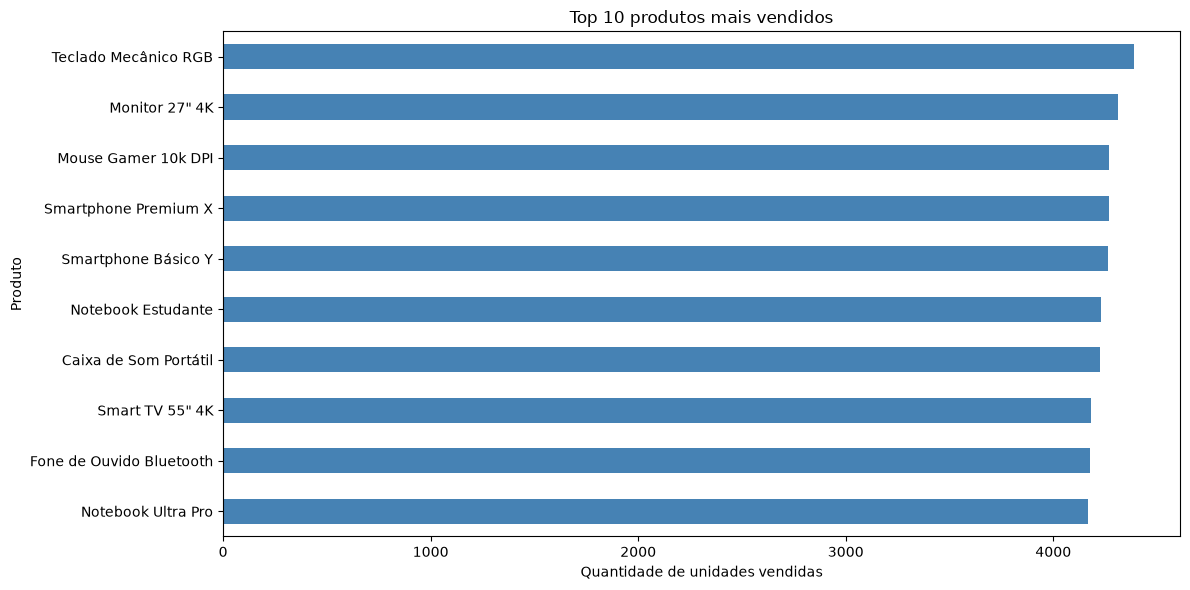

In [6]:
#Agrupando os produtos por quantidade vendida
produtos_mais_vendidos = (
    df_concluidas.groupby("nome_produto")["quantidade"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(produtos_mais_vendidos)

#GRAFICO 01
import matplotlib.pyplot as plt

produtos_mais_vendidos.sort_values().plot(
    kind="barh",
    figsize=(12, 6),
    color="steelblue"
)

plt.title("Top 10 produtos mais vendidos")
plt.xlabel("Quantidade de unidades vendidas")
plt.ylabel("Produto")
plt.tight_layout()
plt.show()


### Conclusão

O Teclado Mecânico RGB foi o produto mais vendido,
com 4.391 unidades comercializadas, seguido pelo
Monitor 27" 4K, com 4.314 unidades.

O gráfico demonstra uma distribuição equilibrada
entre os dez produtos mais vendidos, sem grandes
diferenças no volume de unidades comercializadas.

# 5. Desempenho por Categoria:
Identifique as categorias de produtos que geraram o maior
volume financeiro para a empresa. Compare esses valores.

categoria_produto
Informática    59464270.43
Eletrônicos    43716188.67
Acessórios      4492688.29
Áudio           2963537.37
Name: valor_total, dtype: float64

categoria_produto
Informática    53.75
Eletrônicos    39.51
Acessórios      4.06
Áudio           2.68
Name: valor_total, dtype: float64

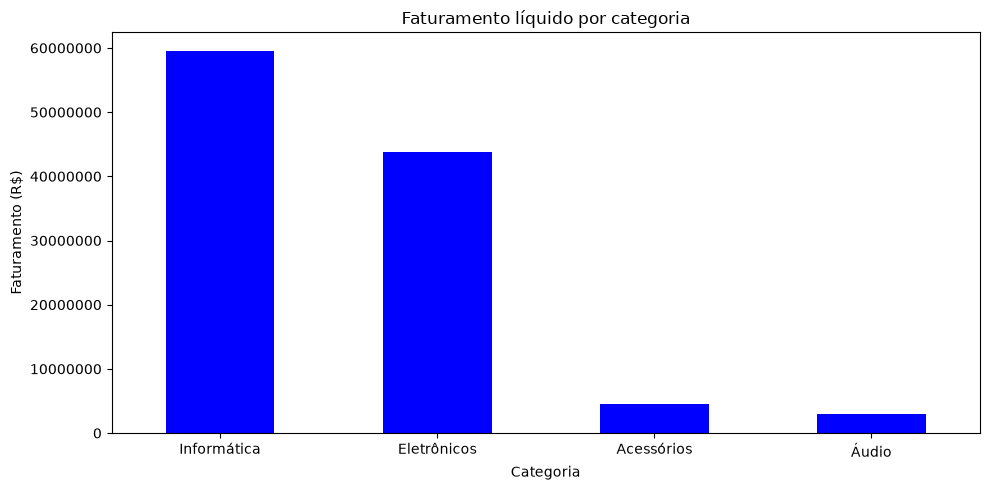

In [7]:
#Calculando faturamento liquido por categoria

faturamento_categoria = (
    df_concluidas.groupby("categoria_produto")["valor_total"]
    .sum()
    .sort_values(ascending=False)
)

display(faturamento_categoria)

#Percentual de cada categoria
participacao_categoria = (
    faturamento_categoria / faturamento_categoria.sum() * 100
)

display(participacao_categoria.round(2))

#GRAFICO 2
faturamento_categoria.plot(
    kind="bar",
    figsize=(10, 5),
    color="blue"
)

plt.title("Faturamento líquido por categoria")
plt.xlabel("Categoria")
plt.ylabel("Faturamento (R$)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Conclusão

A categoria Informática apresentou o maior faturamento
líquido, com R$ 59.464.270,43, representando 53,75%
da receita total da empresa.

Em segundo lugar, destacou-se a categoria Eletrônicos,
com R$ 43.716.188,67, representando 39,51%.

O gráfico demonstra uma elevada concentração do
faturamento nas categorias Informática e Eletrônicos,
que juntas representam aproximadamente 93,26% da receita.

As categorias Acessórios e Áudio apresentaram menor
participação no desempenho financeiro da empresa.

#  6. Sazonalidade e Evolução:
Analise a evolução temporal das vendas ao longo dos meses e anos
disponíveis. Identifique quais foram os períodos de maior e menor faturamento histórico.


ano_mes
2021-01    3124878.08
2021-02    2361780.41
2021-03    2977542.41
2021-04    2731491.93
2021-05    2970433.36
2021-06    2671422.84
2021-07    3061916.64
2021-08    3083492.28
2021-09    2926274.13
2021-10    3011405.52
2021-11    3781028.21
2021-12    4164758.49
2022-01    3123322.22
2022-02    2646441.06
2022-03    2978811.15
2022-04    2766831.75
2022-05    3043099.82
2022-06    2963188.43
2022-07    2486530.65
2022-08    3109442.82
2022-09    3090207.98
2022-10    2620232.89
2022-11    3718965.37
2022-12    3686657.35
2023-01    3309704.83
2023-02    2974367.62
2023-03    2659782.91
2023-04    3135208.87
2023-05    3234396.21
2023-06    2860905.38
2023-07    3056044.46
2023-08    3427870.36
2023-09    2731015.27
2023-10    3244639.01
2023-11    3249351.93
2023-12    3402621.41
Freq: M, Name: valor_total, dtype: float64

ano
2021    36866424.30
2022    36233731.49
2023    37285908.26
Name: valor_total, dtype: float64

Mês de maior faturamento: 2021-12
Valor: R$ 4,164,758.49

Mês de menor faturamento: 2021-02
Valor: R$ 2,361,780.41

Ano de maior faturamento: 2023
Valor: R$ 37,285,908.26

Ano de menor faturamento: 2022
Valor: R$ 36,233,731.49


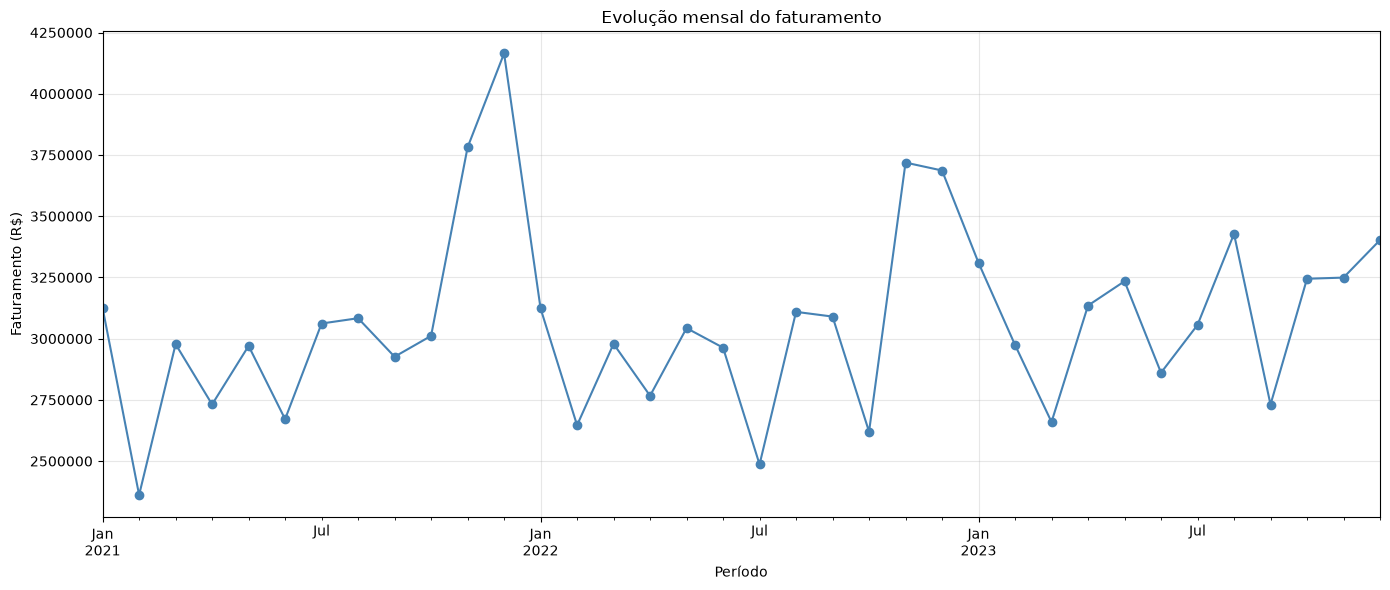

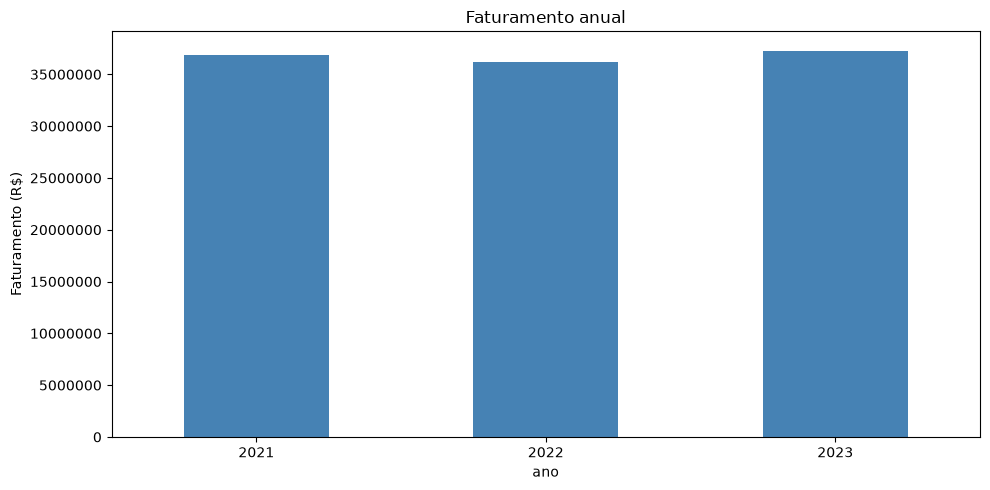

In [8]:
#FATURAMENTO MENSAL
#Vendas concluidas com datas válidas
df_vendas_temporal = df_concluidas.dropna(
    subset=["data_venda"]
).copy()

#criando coluna ano e mês
df_vendas_temporal["ano_mes"] = (
    df_vendas_temporal["data_venda"].dt.to_period("M")
)

#Calculando faturamento mensal
faturamento_mensal = (
    df_vendas_temporal.groupby("ano_mes")["valor_total"]
    .sum()
    .sort_index()
)

display(faturamento_mensal)

#FATURAMENTO ANUAL
#criando coluna ano
df_vendas_temporal["ano"] = (
    df_vendas_temporal["data_venda"].dt.year
)

#Calculando
faturamento_anual = (
    df_vendas_temporal.groupby("ano")["valor_total"]
    .sum()
)

display(faturamento_anual)

#Mostrando periodos de maior e menor faturamento

print("Mês de maior faturamento:", faturamento_mensal.idxmax())
print(f"Valor: R$ {faturamento_mensal.max():,.2f}")

print("\nMês de menor faturamento:", faturamento_mensal.idxmin())
print(f"Valor: R$ {faturamento_mensal.min():,.2f}")

print("\nAno de maior faturamento:", faturamento_anual.idxmax())
print(f"Valor: R$ {faturamento_anual.max():,.2f}")

print("\nAno de menor faturamento:", faturamento_anual.idxmin())
print(f"Valor: R$ {faturamento_anual.min():,.2f}")

#GRAFICO 3 EVOLUÇÃO MENSAL FATURAMENTO
faturamento_mensal.plot(
    kind="line",
    figsize=(14, 6),
    marker="o",
    color="steelblue"
)

plt.title("Evolução mensal do faturamento")
plt.xlabel("Período")
plt.ylabel("Faturamento (R$)")
plt.ticklabel_format(style="plain", axis="y")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#GRAFICO 4 FATURAMENTO ANUAL
faturamento_anual.plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)
plt.title("Faturamento anual")
plt.xlabel("ano")
plt.ylabel("Faturamento (R$)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Conclusão

A análise temporal demonstrou que dezembro de 2021
foi o mês de maior faturamento, atingindo 4.164.758,49,
enquanto fevereiro de 2021 apresentou o menor resultado,
com 2.361.780,41.

O gráfico mensal demonstra uma tendência de aumento
do faturamento nos últimos meses do ano, indicando
possível sazonalidade comercial.

O gráfico anual demonstra estabilidade no faturamento,
com uma redução de 1,72% em 2022 e uma recuperação
de 2,90% em 2023.

O ano de 2023 apresentou o melhor desempenho financeiro,
com faturamento de 37.285.908,26.

Os registros com datas inválidas foram desconsiderados
nesta análise.

# 7. Avaliação de Equipe
Identifique os 5 vendedores com melhor desempenho financeiro e
compare os seus resultados. Apresente também o ticket médio de cada um destes vendedores.

,faturamento,total_pedidos,ticket_medio
nome_vendedor,,,
Carlos Eduardo,8132988.27,1674,4858.42
Fernanda Alves,7855462.08,1683,4667.54
Otávio Borges,7705379.77,1607,4794.88
Diana Souza,7503747.15,1610,4660.71
Gabriel Gomes,7460999.19,1650,4521.82


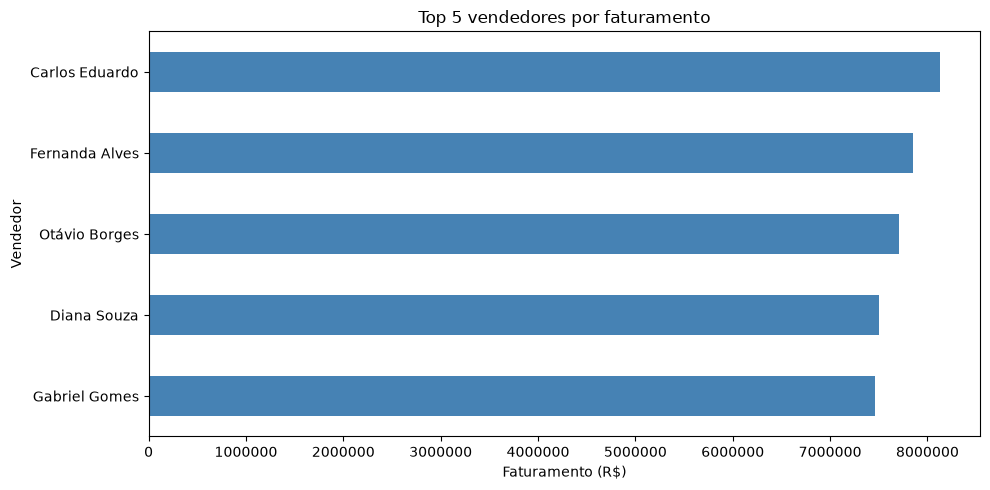

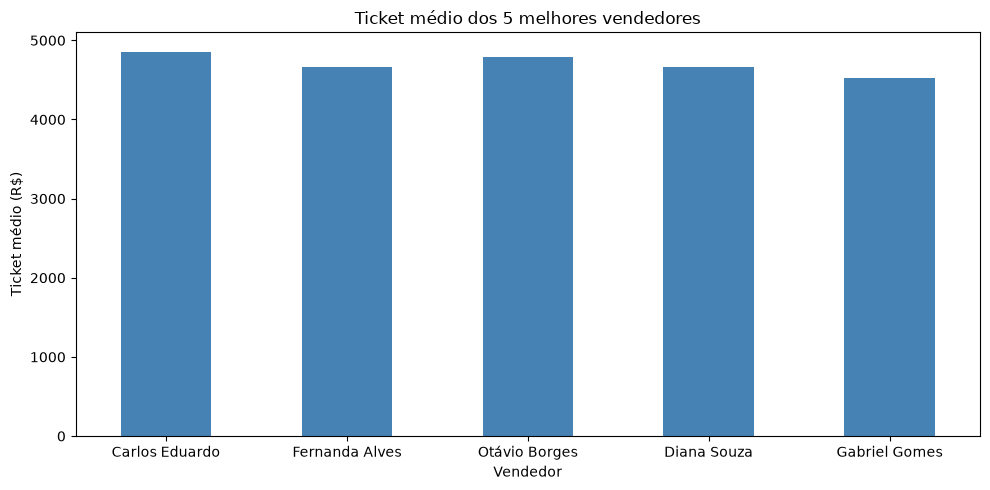

In [12]:
#Separando resultados por vendedor
desempenho_vendedores = (
    df_concluidas.groupby("nome_vendedor")
    .agg(
        faturamento=("valor_total", "sum"),
        total_pedidos=("id_pedido", "nunique")
    )
)

#Calculando ticket médio
desempenho_vendedores["ticket_medio"] = (
    desempenho_vendedores["faturamento"] /
    desempenho_vendedores["total_pedidos"]
)

#Separando 5 melhores vendedores
top_vendedores = (
    desempenho_vendedores
    .sort_values("faturamento", ascending=False)
    .head(5)
)

display(top_vendedores.round(2))

#GRAFICO 05 FATURAMENTO MELHORES VENDEDORES
top_vendedores["faturamento"].sort_values().plot(
    kind="barh",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("Top 5 vendedores por faturamento")
plt.xlabel("Faturamento (R$)")
plt.ylabel("Vendedor")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

#GRAFICO 06 TICKET MÉDIO POR VENDEDOR
top_vendedores["ticket_medio"].plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("Ticket médio dos 5 melhores vendedores")
plt.xlabel("Vendedor")
plt.ylabel("Ticket médio (R$)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Conclusão

Carlos Eduardo apresentou o melhor desempenho financeiro,
com faturamento de 8.132.988,27 e ticket médio
de 4.858,42.

Fernanda Alves apresentou a maior quantidade de pedidos
entre os cinco vendedores, totalizando 1.683.

O gráfico de faturamento demonstra um desempenho
relativamente equilibrado entre os cinco vendedores.

O gráfico de ticket médio evidencia que Carlos Eduardo
e Otávio Borges obtiveram os maiores valores médios
por pedido entre os vendedores analisados.

# 8. Preferências de Pagamento
Analise as formas de pagamento utilizadas pelos clientes. Qual é
a participação percentual de cada método no total de transações concluídas?

,total_pedidos,percentual
forma_pagamento,,
Cartão de Crédito,6158,25.34
Boleto,6134,25.24
PIX,6124,25.20
Cartão de Débito,5889,24.23


Pedidos com mais de uma forma de pagamento: 0


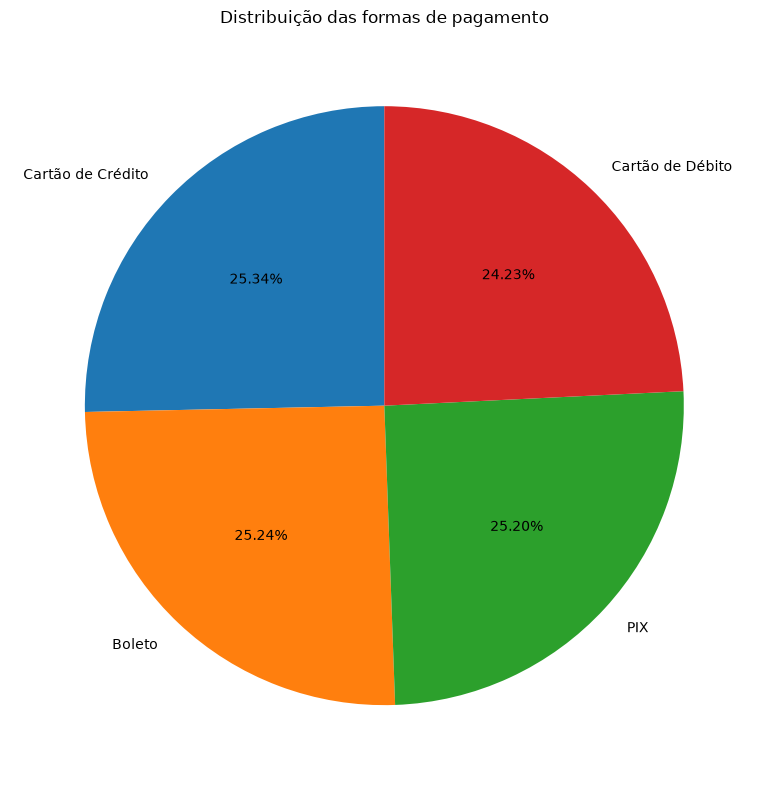

In [10]:
#Pedidos por forma de pagamento
formas_pagamento = (
    df_concluidas.groupby("forma_pagamento")["id_pedido"]
    .nunique()
    .sort_values(ascending=False)
)

#Calculando a participação percentual
percentual_pagamento = (
    formas_pagamento / formas_pagamento.sum() * 100
)

#Organizando os resultados em uma tabela
analise_pagamento = pd.DataFrame({
    "total_pedidos": formas_pagamento,
    "percentual": percentual_pagamento.round(2)
})

display(analise_pagamento)

#Pedidos com mais de uma forma de pagamento
print("Pedidos com mais de uma forma de pagamento:",
      (df_concluidas.groupby("id_pedido")["forma_pagamento"]
      .nunique() > 1 ).sum())

#GRAFICO 07 DISTRIBUIÇÃO DE FORMAS DE PAGAMENTO
formas_pagamento.plot(
    kind="pie",
    figsize=(8, 8),
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Distribuição das formas de pagamento")
plt.ylabel("")
plt.tight_layout()
plt.show()




### Conclusão

O cartão de crédito foi a forma de pagamento mais
utilizada, representando 25,34% dos pedidos concluídos,
seguido pelo boleto, com 25,24%, e pelo PIX, com 25,20%.

O gráfico demonstra uma distribuição equilibrada
entre as quatro formas de pagamento, sem predominância
expressiva de um método específico.

Esse resultado indica a importância de manter
diferentes opções de pagamento disponíveis aos clientes.

# 9. Análise Geográfica
Compare o desempenho comercial entre os estados (UF) presentes na
base. Quais regiões apresentam maior aderência aos produtos da empresa?

,faturamento,unidades_vendidas,total_pedidos,participacao
estado_cliente,,,,
PR,11614642.97,6509,2494,10.50
SC,11328216.07,6387,2427,10.24
SP,11136545.89,6296,2426,10.07
MG,11113253.06,6267,2436,10.04
BA,11112591.29,6192,2352,10.04
DF,11049159.98,6435,2459,9.99
RJ,11038777.38,6269,2444,9.98
PE,10987283.83,6244,2421,9.93
GO,10968952.25,6205,2441,9.91


,faturamento,unidades_vendidas,total_pedidos
regiao,,,
Sudeste,33288576.33,18832,7306
Sul,33230121.08,19098,7326
Nordeste,22099875.12,12436,4773
Centro-Oeste,22018112.23,12640,4900


,faturamento,unidades_vendidas,total_pedidos
regiao,,,
Sudeste,33288576.33,18832,7306
Sul,33230121.08,19098,7326
Nordeste,22099875.12,12436,4773
Centro-Oeste,22018112.23,12640,4900


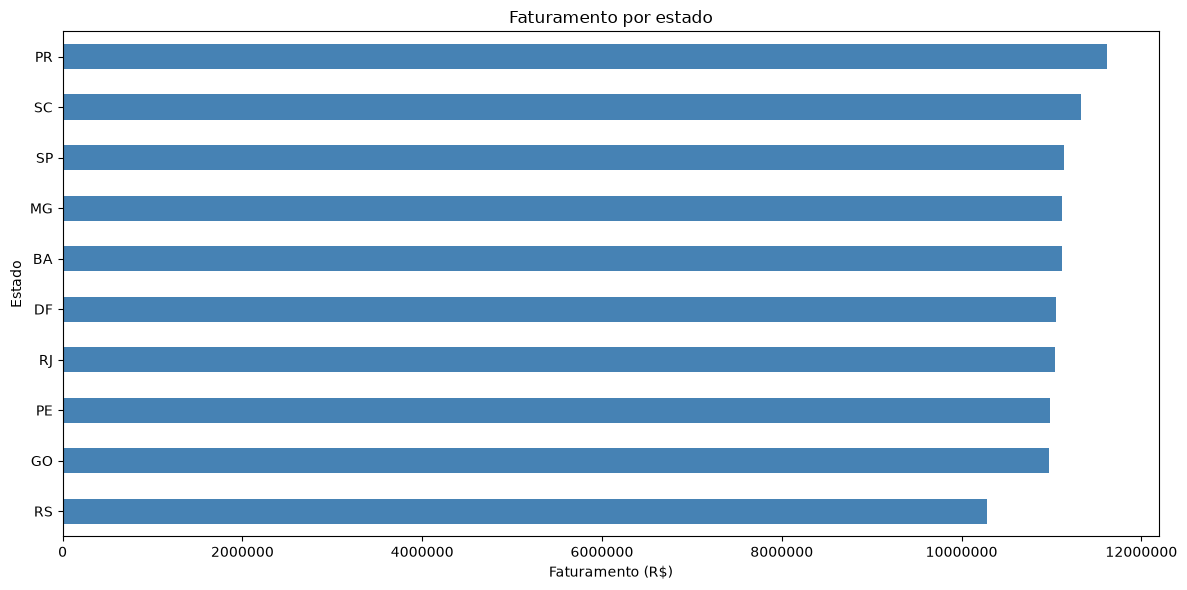

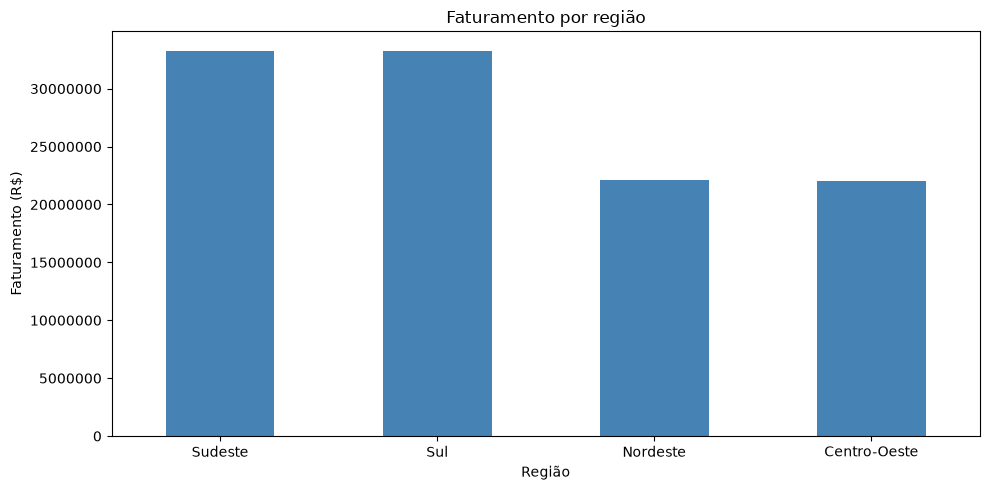

In [11]:
#Faturamento por estado
# Calculando o desempenho comercial por estado
desempenho_estados = (
    df_concluidas.groupby("estado_cliente")
    .agg(
        faturamento=("valor_total", "sum"),
        unidades_vendidas=("quantidade", "sum"),
        total_pedidos=("id_pedido", "nunique")
    )
    .sort_values("faturamento", ascending=False)
)

# Calculando a participação no faturamento
desempenho_estados["participacao"] = (
    desempenho_estados["faturamento"] / faturamento_liquido * 100
)

display(desempenho_estados.round(2))

#Faturamento por região
#Relacionando os estados às suas regiões
regioes = {
    "SP": "Sudeste",
    "RJ": "Sudeste",
    "MG": "Sudeste",
    "RS": "Sul",
    "PR": "Sul",
    "SC": "Sul",
    "GO": "Centro-Oeste",
    "DF": "Centro-Oeste",
    "PE": "Nordeste",
    "BA": "Nordeste"
}

# Criando a coluna região
df_concluidas["regiao"] = (
    df_concluidas["estado_cliente"].map(regioes)
)

# Calculando o desempenho por região
desempenho_regioes = (
    df_concluidas.groupby("regiao")
    .agg(
        faturamento=("valor_total", "sum"),
        unidades_vendidas=("quantidade", "sum"),
        total_pedidos=("id_pedido", "nunique")
    )
    .sort_values("faturamento", ascending=False)
)

display(desempenho_regioes.round(2))

# Relacionando os estados às suas regiões
regioes = {
    "SP": "Sudeste",
    "RJ": "Sudeste",
    "MG": "Sudeste",
    "RS": "Sul",
    "PR": "Sul",
    "SC": "Sul",
    "GO": "Centro-Oeste",
    "DF": "Centro-Oeste",
    "PE": "Nordeste",
    "BA": "Nordeste"
}

# Criando a coluna região
df_concluidas["regiao"] = (
    df_concluidas["estado_cliente"].map(regioes)
)

# Calculando o desempenho por região
desempenho_regioes = (
    df_concluidas.groupby("regiao")
    .agg(
        faturamento=("valor_total", "sum"),
        unidades_vendidas=("quantidade", "sum"),
        total_pedidos=("id_pedido", "nunique")
    )
    .sort_values("faturamento", ascending=False)
)

display(desempenho_regioes.round(2))

#GRAFICO 08 FATURAMENTO POR ESTADO
desempenho_estados["faturamento"].sort_values().plot(
    kind="barh",
    figsize=(12, 6),
    color="steelblue"
)

plt.title("Faturamento por estado")
plt.xlabel("Faturamento (R$)")
plt.ylabel("Estado")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

#GRAFICO 09 FATURAMENTO POR REGIAO
desempenho_regioes["faturamento"].plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("Faturamento por região")
plt.xlabel("Região")
plt.ylabel("Faturamento (R$)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Conclusão

O Paraná apresentou o maior faturamento entre os estados,
com 11.614.642,97, seguido por Santa Catarina.
O Rio Grande do Sul apresentou o menor faturamento,
com 10.287.262,04.
O gráfico por estado demonstra uma distribuição
relativamente equilibrada do faturamento.
Na análise regional, o Sudeste apresentou o maior
faturamento, enquanto a região Sul liderou em quantidade
de unidades vendidas e número de pedidos.
As regiões Sul e Sudeste apresentaram os melhores
resultados comerciais. Entretanto, ambas possuem mais
estados representados na base de dados.

# 10. Visualização de Dados
Construa e apresente pelo menos 6 (seis) gráficos relevantes que
ajudem a ilustrar visualmente os resultados encontrados nas questões anteriores. Abaixo de cada
gráfico, explique brevemente o que a visualização demonstra.

# 10. Resolução:
Ao longo do projeto, foram desenvolvidos nove gráficos
utilizando a biblioteca Matplotlib.
As visualizações foram distribuídas entre as questões
anteriores, facilitando a interpretação dos resultados
e a identificação de padrões comerciais, financeiros,
temporais e geográficos.
Foram utilizados gráficos de barras, linhas e setores,
de acordo com as características de cada análise.

#  Questão 11 — Estudo Aplicado

### Pergunta de negócio

Quais regiões e categorias de produtos devem receber
maior investimento em marketing e força de vendas
no próximo trimestre?

### Metodologia

Foi realizado o cruzamento entre região geográfica
e categoria de produto, utilizando o faturamento
líquido das vendas concluídas para identificar
as melhores oportunidades comerciais.

In [13]:
# Calculando o faturamento por região e categoria
analise_estrategica = (
    df_concluidas.groupby(["regiao", "categoria_produto"])["valor_total"]
    .sum()
    .unstack()
)

display(analise_estrategica.round(2))

categoria_produto,Acessórios,Eletrônicos,Informática,Áudio
regiao,,,,
Centro-Oeste,905794.03,8662188.71,11869086.33,581043.16
Nordeste,905680.78,9026797.99,11581860.58,585535.77
Sudeste,1354344.72,13100599.78,17984554.25,849077.58
Sul,1326868.76,12926602.19,18028769.27,947880.86


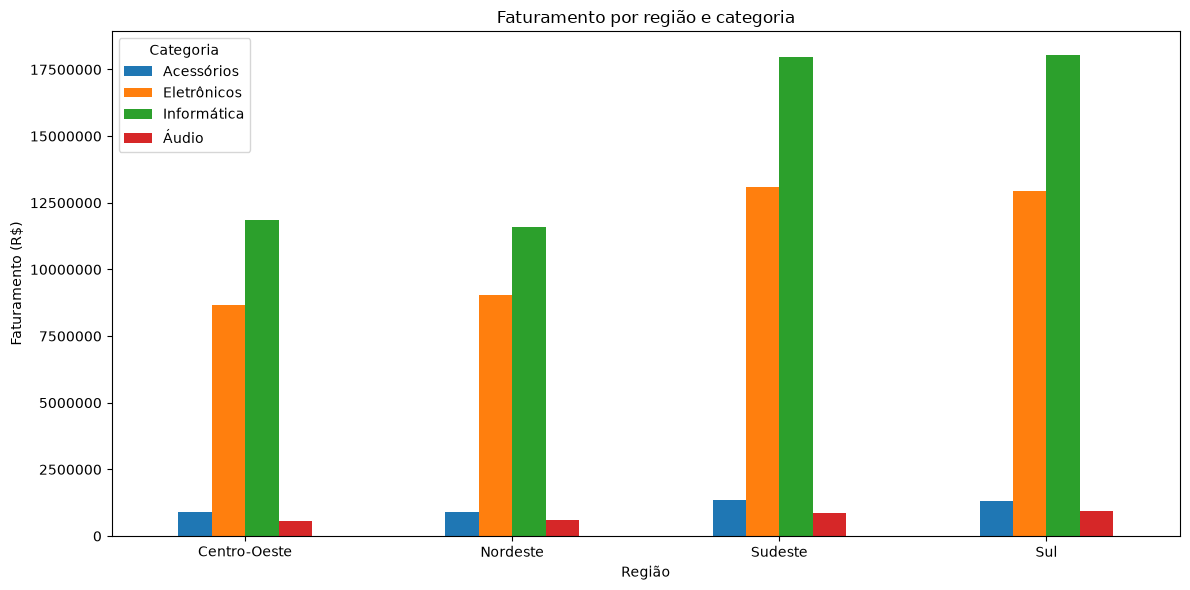

In [14]:
analise_estrategica.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Faturamento por região e categoria")
plt.xlabel("Região")
plt.ylabel("Faturamento (R$)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=0)
plt.legend(title="Categoria")
plt.tight_layout()
plt.show()

# Questão 11 -  Conclusão
As categorias Informática e Eletrônicos lideram o faturamento em todas as regiões, com destaque para o Sul e o Sudeste, que juntas geraram aproximadamente R$ 62 milhões nessas categorias.
Com base no faturamento histórico, recomenda-se priorizar essas regiões e categorias na distribuição do orçamento de marketing e da força de vendas para o próximo trimestre.